In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'tensorflow', 'keras', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'keras': 'keras==3.14.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'tensorflow.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# AlexNet and Learned Image Representations

The LeNet of that section learns everything it computes from examples,
its convolution kernels as well as its classifier. LeCun and his colleagues
trained the first such network in 1989, yet for the next two decades most
vision systems worked differently. They separated representation from
prediction: hand-designed operators such as SIFT [@Lowe.2004], SURF
[@Bay.Tuytelaars.Van-Gool.2006], HOG [@Dalal.Triggs.2005], and bags
of visual words [@Sivic.Zisserman.2003] turned pixels into feature
vectors, and a linear or kernel method learned a classifier on top. The
training loss could improve the classifier but never the features, so
progress depended on people inventing better features. Why did learned
features take so long to beat engineered ones, and what changed when they
did?

The change came at the ImageNet challenge of 2012, which asked a system to
sort photographs into 1000 categories and scored it by its *top-5 error*, the
fraction of test images whose correct label is not among the system's five
best guesses. The winners of the two previous years, both built on engineered
features, had top-5 errors of about 28% and 26%. AlexNet
[@Krizhevsky.Sutskever.Hinton.2012] replaced the two-stage pipeline with
one deep convolutional network trained end to end, and reached a top-5 error
of 15.3%, against 26.2% for the next-best entry. Its architecture is the
template of LeNet scaled up: convolutional stages that shrink the resolution
and grow the number of channels, followed by fully connected layers. Three
things made the scale-up work in 2012 when it had not before: a labeled
dataset large enough for tens of millions of parameters, GPUs fast enough to
train them in days, and techniques (ReLU activations, dropout, data
augmentation) that kept a network of this size trainable and kept it from
overfitting.

This section explains why each of the three mattered, builds AlexNet, counts
where its parameters and its arithmetic sit, and trains it on Fashion-MNIST.
The count exposes the cost that the next section removes: almost all of
AlexNet's parameters sit in two fully connected layers.

In [ ]:
import math
import numpy as np
import tensorflow as tf
from d2l import tensorflow as d2l

## Learned Features, Data, and Hardware

A representation is learned when the loss decides what the features compute.
The idea is old: LeNet learned its convolution kernels from examples, and
sparse coding learned image filters without labels
[@olshausen1996emergence]. Until 2012, however, learned features had not
beaten engineered ones on a large benchmark. AlexNet's did, and its first
layer shows what the network chose to compute. the figure displays
its 96 learned kernels of $11 \times 11$ pixels: oriented edges at several
frequencies and patches of color, close to the oriented-gradient operators
that SIFT and HOG compute by design. The network found these operators
because they reduce the classification loss, and it found the operators of
its higher layers the same way, where no designer had a good guess to offer.

![The 96 kernels of the first convolutional layer of AlexNet, learned on ImageNet. Reproduction courtesy of @Krizhevsky.Sutskever.Hinton.2012.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/filters.png)

LeNet and AlexNet share most of their design, and LeNet was trained end to
end in 1989. The two decades in between supplied what a network of tens of
millions of parameters needs: data to constrain its parameters and hardware
to compute its gradients.

### Data

A model with tens of millions of parameters, fitted to a few thousand images,
memorizes them. The PASCAL VOC benchmark of the same years had about ten
thousand images in 20 classes. The ImageNet dataset
[@Deng.Dong.Socher.ea.2009] changed the scale: its 2012 challenge
[@russakovsky2015imagenet] supplied about 1.2 million training images in
1000 categories, collected by web image search for the categories of WordNet
[@Miller.1995] and verified by workers on Amazon Mechanical Turk. The
images came at varying resolutions, and AlexNet trained on random
$224 \times 224$ crops of images rescaled to $256 \times 256$, and on their
mirror images. A crop can start at any of about $32 \times 32$ offsets and
can be mirrored or not, so each image yields about
$32 \cdot 32 \cdot 2 = 2{,}048$ different inputs, the factor the paper
counts. Even with this much data the network overfit without
dropout [@Krizhevsky.Sutskever.Hinton.2012].

### Hardware

Training a deep network repeats the same small computations at enormous
scale. A convolution applies one kernel at every output position and every
channel, and each of these products is independent of the others. A
*graphics processing unit* (GPU) is built for such work: instead of a few
fast cores with branch predictors, speculative execution, and large caches,
it has hundreds or thousands of simple cores and a much wider memory bus.
In the mid-2000s, NVIDIA and ATI began to make these chips programmable
for general computation [@Fernando.2004]. Each of the two NVIDIA GTX 580s
on which AlexNet was trained performs about 1.6 trillion floating-point
operations per second (TFLOPS) in single precision and reads 192 GB of memory
per second; a quad-core desktop CPU of 2011 peaked at about 0.2 TFLOPS and
20 GB/s.

A short calculation shows why this mattered. A network of AlexNet's size
needs about a billion multiply-adds to classify one $224 \times 224$ color
image, and a training step costs about three times as
many, for the forward pass and the two products of the backward pass. With
two floating-point operations per multiply-add, the 90 passes over 1.2
million images used in the paper take about $10^9 \cdot 3 \cdot 2 \cdot 1.2
\times 10^6 \cdot 90 \approx 6.5 \times 10^{17}$ operations. The two GPUs
need two to three days for that at their peak, and the actual run took five
to six days. A CPU at its peak would have needed more than a month. Alex
Krizhevsky wrote the convolution kernels for the GPUs himself; his
[cuda-convnet](https://code.google.com/archive/p/cuda-convnet/) code remained
in wide use for several years, until frameworks made the same network a
dozen lines of code, as below.

## The AlexNet Architecture

the figure places AlexNet beside the LeNet of
that section, both in the versions that this book trains on
Fashion-MNIST. Both consist of convolutional stages followed by a fully
connected head; AlexNet changes the size of every part and three of its
components.

![LeNet as built in that section (left) and AlexNet as built in this section (right), both for single-channel Fashion-MNIST images and ten classes; the input is at the bottom. AlexNet is deeper and wider, uses ReLU activations and max-pooling, and regularizes its dense layers with dropout.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/arch-alexnet.svg)

### Depth and Width

AlexNet has eight layers with weights: five convolutional layers and three
fully connected layers, against LeNet's two and three. Its images are eight
times wider and taller than Fashion-MNIST's, so the first layer uses an
$11 \times 11$ kernel with stride 4 to cover a large patch of the image at
once and to reduce the resolution early. The second layer uses
$5 \times 5$ kernels and the last three $3 \times 3$ kernels. Max-pooling
with $3 \times 3$ windows and stride 2 follows the first, second, and fifth
convolutional layers. The convolutional layers have 96 to 384 channels,
where LeNet's have 6 and 16, and the two hidden fully connected layers have
4096 units each, where LeNet's have 120 and 84.

Our version simplifies the network of the paper in two ways. The paper split
every layer between two GPUs of 3 GB each, which could not hold the whole
model, and restricted some layers to their own GPU's half of the channels; a
single GPU now holds the model, so our version has no split. The paper also
normalized each activation by the activations of neighboring channels, a
step that later networks dropped.

### ReLU Activations

LeNet uses saturating activations: the sigmoid in our version, a scaled
$\tanh$ in the original of 1998. The derivative of the sigmoid,
$\sigma'(x) = \sigma(x)(1 - \sigma(x))$, is at most $1/4$. Each sigmoid that
the gradient passes on its way back to the first layer multiplies it by this
derivative, so the sigmoids contribute a factor of at most $1/4$ each
(that section). This is
why LeNet needed a learning rate of 2.0. AlexNet uses the ReLU,
$\textrm{ReLU}(x) = \max(x, 0)$ (that section),
whose derivative is 1 for every positive input, so the gradient passes the
active units of a layer unchanged, however many layers lie in between. The
ReLU is also cheaper to compute, since it needs no exponential. On a small
convolutional network for CIFAR-10, @Krizhevsky.Sutskever.Hinton.2012
reached a training error of 25% six times faster with ReLUs than with
$\tanh$.

### Dropout and Augmentation

The two fully connected layers of 4096 units hold most of the parameters and
are where the model can memorize the training set. AlexNet applies dropout
with probability 0.5 to their outputs (that section), whereas LeNet
has no explicit regularizer. The crops and mirror images described above,
together with random changes of color, add variation to the input. Data
augmentation has since become a large part of how convolutional networks are
trained; that section returns to it.

### Implementation

The code mirrors the figure from bottom to top. We initialize the
weights explicitly instead of relying on the library's defaults. LeNet's
Xavier initialization keeps the variance of the activations constant through
linear layers; a ReLU sets about half of its inputs to zero and halves the
second moment of what passes through it. *He initialization*
(that section) compensates by doubling the variance: every weight
of a layer with $n_\textrm{in}$ inputs per output is drawn from a normal
distribution with mean zero and variance $2/n_\textrm{in}$, where
$n_\textrm{in} = c_\textrm{i} k^2$ for a convolution. All biases start at
zero.

Every layer receives its own initializer, since an unseeded Keras initializer
returns the same values on every call; Keras initializes biases to zero.

In [2]:
class AlexNet(d2l.Classifier):
    def __init__(self, lr=0.1, num_steps=4690, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        layers = tf.keras.layers

        def he():  # A new He-normal initializer for each layer
            init = tf.keras.initializers.VarianceScaling(
                2.0, 'fan_in', 'untruncated_normal')
            return dict(kernel_initializer=init)

        self.net = tf.keras.models.Sequential([
            layers.Conv2D(96, kernel_size=11, strides=4, activation='relu',
                          **he()),
            layers.MaxPool2D(pool_size=3, strides=2),
            layers.Conv2D(256, kernel_size=5, padding='same',
                          activation='relu', **he()),
            layers.MaxPool2D(pool_size=3, strides=2),
            layers.Conv2D(384, kernel_size=3, padding='same',
                          activation='relu', **he()),
            layers.Conv2D(384, kernel_size=3, padding='same',
                          activation='relu', **he()),
            layers.Conv2D(256, kernel_size=3, padding='same',
                          activation='relu', **he()),
            layers.MaxPool2D(pool_size=3, strides=2), layers.Flatten(),
            layers.Dense(4096, activation='relu', **he()), layers.Dropout(0.5),
            layers.Dense(4096, activation='relu', **he()), layers.Dropout(0.5),
            layers.Dense(num_classes, **he())])

To check the code against the figure, we pass a single-channel
$224 \times 224$ image through the network and print the output shape of each
layer.

In [3]:
AlexNet().layer_summary((1, 224, 224, 1))

Conv2D                 (1, 54, 54, 96)
MaxPooling2D           (1, 26, 26, 96)
Conv2D                 (1, 26, 26, 256)
MaxPooling2D           (1, 12, 12, 256)
Conv2D                 (1, 12, 12, 384)


Conv2D                 (1, 12, 12, 384)
Conv2D                 (1, 12, 12, 256)
MaxPooling2D           (1, 5, 5, 256)
Flatten                (1, 6400)
Dense                  (1, 4096)
Dropout                (1, 4096)
Dense                  (1, 4096)
Dropout                (1, 4096)
Dense                  (1, 10)


The shapes follow the rules of that section. The first convolution
maps 224 to $\lfloor (224 - 11)/4 \rfloor + 1 = 54$, and each $3 \times 3$
pooling with stride 2 maps $n$ to $\lfloor (n - 3)/2 \rfloor + 1$: 54 to 26,
26 to 12, and 12 to 5. The padded convolutions in between keep the
resolution, so the last convolutional stage hands $256 \times 5 \times 5 =
6400$ numbers to the first fully connected layer.

### Parameters and Multiply-Adds

The shapes determine the size and the cost of every layer, counted as for
LeNet: a convolutional layer with $c_\textrm{i}$ input channels,
$c_\textrm{o}$ output channels, and a $k \times k$ kernel has
$c_\textrm{i} c_\textrm{o} k^2$ weights and $c_\textrm{o}$ biases, and it
applies each weight once at every output position. A fully connected layer
uses each of its weights once per example. the table applies
these counts to AlexNet.

<!-- tbl-caption:Parameters and multiply-adds per example of the layers of AlexNet, for one single-channel $224 \times 224$ image and ten classes. Pooling, activation, and dropout layers have no parameters. -->

| layer | output | parameters | multiply-adds |
|:--|:--|--:|--:|
| $11\times11$ convolution, 1 to 96, stride 4 | 96@54×54 | $11{,}712$ | $33.9$M |
| $5\times5$ convolution, 96 to 256 | 256@26×26 | $614{,}656$ | $415.3$M |
| $3\times3$ convolution, 256 to 384 | 384@12×12 | $885{,}120$ | $127.4$M |
| $3\times3$ convolution, 384 to 384 | 384@12×12 | $1{,}327{,}488$ | $191.1$M |
| $3\times3$ convolution, 384 to 256 | 256@12×12 | $884{,}992$ | $127.4$M |
| fully connected, 6400 to 4096 | 4096 | $26{,}218{,}496$ | $26.2$M |
| fully connected, 4096 to 4096 | 4096 | $16{,}781{,}312$ | $16.8$M |
| fully connected, 4096 to 10 | 10 | $40{,}970$ | $0.04$M |
| total | | $46{,}764{,}746$ | $938.1$M |

The two kinds of layers divide the work as in LeNet, only more sharply. The
convolutional layers hold 8% of the 47 million parameters and perform 95% of
the multiply-adds. The fully connected layers hold the other 92% of the
parameters, about 170 MB in 32-bit floating point, and perform 5% of the
arithmetic; the first of them alone holds 26 million parameters. Against
LeNet's 61,706 parameters and 416,520 multiply-adds per image, AlexNet has
about 760 times the parameters and performs about 2,250 times the arithmetic.
The network of the paper, with three input channels and 1000 classes, has
about 60 million parameters, most of them in the same fully connected layers.

## Training on Fashion-MNIST

Training AlexNet on ImageNet takes days even on a modern GPU, so we train it
on Fashion-MNIST, as we did LeNet. Its $28 \times 28$ images are too small
for an $11 \times 11$ kernel with stride 4, so we upsample them to
$224 \times 224$ with the `resize` argument of `d2l.FashionMNIST`.
Upsampling multiplies the number of pixels by 64 without adding
information; we accept the cost to train the architecture as it is.

We train with minibatch SGD for 10 epochs, a third of LeNet's 30, with
minibatches of 128 images. LeNet's sigmoids needed a learning rate of 2.0 to
move its first layers at all; with ReLUs the gradient no longer shrinks at
every layer, and a much smaller rate suffices.

We also change the learning rate during training, as AlexNet's authors did:
they divided it by 10 whenever the validation error stopped improving. At
the start the weights are random, and a full-size step can throw the network
into a region from which it recovers only slowly. At the end, a large rate
keeps the weights jumping around a good solution instead of settling into
it. A common schedule handles both ends. A linear *warmup* raises the rate
from zero to its peak $\eta_0$ over the first $t_\textrm{w}$ steps, and a
half-cosine then lowers it to zero at the last step $T$:

$$
\eta_t = \frac{\eta_0}{2} \left(1 + \cos \frac{\pi (t - t_{\textrm{w}})}{T - t_{\textrm{w}}}\right)
\quad \textrm{for } t \geq t_{\textrm{w}}.
$$

At $t = t_\textrm{w}$ the cosine is 1 and the rate is $\eta_0$; halfway
through the decay it is $\eta_0/2$; at $t = T$ it is zero. Since the first
steps are small, the peak can be higher than a rate that would be safe from
the first step on; we use 0.03. The function `cosine_warmup` returns the
factor by which the schedule multiplies the peak rate at step $t$; we save
it in the `d2l` package for later sections. that section
compares learning-rate schedules in depth.

In [ ]:
def cosine_warmup(t, num_steps, warmup_steps):
    """Learning-rate factor: linear warmup from 0, then a half-cosine to 0."""
    t = tf.cast(t, tf.float32)  # Also works on the step counter of a graph
    warmup = tf.where(t < warmup_steps, t / warmup_steps, 1.0)
    progress = tf.clip_by_value(
        (t - warmup_steps) / (num_steps - warmup_steps), 0.0, 1.0)
    return warmup * 0.5 * (1 + tf.cos(math.pi * progress))

`AlexNet` steps the schedule after every minibatch. Its argument
`num_steps` is $T$, the number of minibatches in the whole run, and the
warmup covers the first tenth of them: one epoch of the ten.

In [5]:
@d2l.add_to_class(AlexNet)
def configure_optimizers(self):
    schedule = lambda: self.lr * cosine_warmup(
        optim.iterations, self.num_steps, self.num_steps // 10)
    optim = tf.keras.optimizers.SGD(schedule)
    return optim

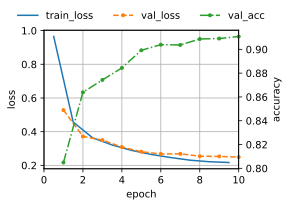

In [6]:
data = d2l.FashionMNIST(batch_size=128, resize=(224, 224))
model = AlexNet(lr=0.03, num_steps=10 * len(data.train_dataloader()))
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
trainer.fit(model, data)

AlexNet reaches a validation accuracy of about 91% after 10 epochs, with a
training loss of about 0.22 and a validation loss of about 0.25. Over the last
epochs, as the learning rate approaches zero, the accuracy changes by less
than a point from one epoch to the next, so the last epoch is a fair summary
of the run.
LeNet reaches about 88–90% after 30 epochs. On these images the larger
network passes LeNet's accuracy in a third of the epochs, but only by a
point or two, while it performs 2,250 times the arithmetic per image: the
upsampled $224 \times 224$ images hold no more information than the
$28 \times 28$ originals. AlexNet's extra capacity helps on ImageNet, whose
images carry far more detail and whose 1000 classes are far harder to tell
apart.

The count of the table also shows where that capacity sits.
Nine of every ten parameters belong to the fully connected head, which
contributes 5% of the arithmetic and needs dropout to keep from memorizing
the training set. The next section asks whether a network needs that head at
all.

## Summary

Before 2012, image classifiers learned a classifier on top of hand-designed
features. AlexNet learned the features as well, with a deep convolutional
network trained end to end, and cut the ImageNet top-5 error from 26% to
15%. Its architecture is LeNet's template, deeper and wider, with ReLU
activations, max-pooling, and dropout; ImageNet's 1.2 million labeled images
and two GPUs made a network of 60 million parameters trainable in days.
Counting its layers shows that the convolutions perform 95% of the
arithmetic while the fully connected head holds 92% of the parameters. On
Fashion-MNIST, trained with a learning rate that warms up and then decays to
zero, AlexNet passes LeNet's accuracy by a point or two in a third of the
epochs, at 2,250 times the arithmetic per image.

## Exercises

1. **Memory and compute ledger.** Extend the table to the
   memory that `AlexNet` needs in 32-bit floating point.
    1. Compute the number of activations that the forward pass of one
       $224 \times 224$ image stores, layer by layer, counting the output
       of every convolutional, pooling, and fully connected layer. Where is
       the memory for activations concentrated, and where is the memory for
       parameters concentrated?
    1. During training, the parameters, their gradients, and the stored
       activations of a whole minibatch must fit in memory. At which batch
       size does the memory for activations exceed the memory for
       parameters and gradients?
    1. Repeat the parameter count of the table for the
       ImageNet version, with three input channels, 1000 classes, and
       $227 \times 227$ inputs, which make the last convolutional stage
       $6 \times 6$ instead of $5 \times 5$. Compare your total with the 60
       million parameters reported by
       @Krizhevsky.Sutskever.Hinton.2012 .

    *Adapted from Simon Prince,
    [Understanding Deep Learning](https://udlbook.github.io/udlbook/),
    Problem 10.16.*

1. **Receptive fields of the early layers.** A stack of layers with kernel
   sizes $k_i$ and strides $s_i$ gives its top unit a receptive field of
   side $r = 1 + \sum_{i} (k_i - 1) \prod_{j<i} s_j$
   (that section). Apply it to `AlexNet`, counting each
   max-pooling layer as a layer with its own kernel size and stride, to
   compute the receptive field of one unit after each of the five
   convolutional layers. What fraction of the $224 \times 224$ input side
   does each receptive field span, and where does a unit first see the
   whole image?

    *Adapted from Simon Prince,
    [Understanding Deep Learning](https://udlbook.github.io/udlbook/),
    Problem 10.17.*

1. [code] **Learned first-layer filters.** the figure shows the
   first-layer kernels that AlexNet learned on ImageNet.
    1. Train `AlexNet` as in this section, keeping a copy of the weights of
       its first convolutional layer from before training. Display the 96
       kernels of $11 \times 11$ pixels at initialization, after training,
       and as the difference between the two.
    1. Compare the change made by training with the figure.
       Name two visible differences and the property of this section's
       input images that causes each.

1. [code] **Dropout.** The fully connected layers of `AlexNet` hold 92% of
   its parameters, and dropout is its only regularizer.
    1. Train `AlexNet` as in this section with both dropout layers removed,
       and compare the training loss, the validation loss, and the
       validation accuracy after 10 epochs with those of the original.
    1. Train both networks on a random subset of 6,000 training images for
       the same number of gradient steps. How do the differences change, and
       why?

1. **Arithmetic intensity.** ● The *arithmetic intensity* of a layer is
   the number of multiply-adds it performs per byte of parameters it reads
   from memory. Use the table.
    1. Compute the arithmetic intensity of every layer of `AlexNet`, once
       for a batch of 1 image and once for a batch of 128 images, assuming
       that each parameter is read once per batch.
    1. Consider a chip that performs 10 multiply-adds in the time it reads
       one byte from memory. Assume that each layer takes the longer of its
       arithmetic time and its parameter-reading time. A designer can spend
       extra chip area on doubling either the arithmetic throughput or the
       memory bandwidth. Which choice speeds up single-image inference more,
       and which speeds up training at batch size 128 more?

1. [code] **Batch size, throughput, and memory.** ● Train `AlexNet` as in
   this section while varying only the batch size.
    1. Using your answer to problem
       1, predict the largest
       training batch size that fits in the memory of your GPU.
    1. Starting from a batch size of 32 and doubling it, find the largest
       batch size that trains without running out of memory. Compare it
       with your prediction and name the main source of any discrepancy.
    1. Measure the throughput in images per second over a fixed number of
       training steps for at least four batch sizes up to that limit.
       Beyond which batch size does throughput stop growing, and why?

[Discussions](https://d2l.discourse.group/t/276)